# Skin_Lesion_Binary_FINAL — The Single Authoritative Training + Deployment Notebook

**This is the last notebook in the project.** Every other notebook will be deleted after this
one is validated. Fully self-contained: trains from scratch, depends on nothing but the
project's immutable dataset split.

## What was kept, what was removed, and why (audit of all prior real experiments)

| Component | Decision | Real evidence this is based on |
|---|---|---|
| EfficientNet-B3 backbone | **Kept** | Consistently the strongest, most stable option across every experiment run in this project; the only backbone with a complete, real, multi-run track record. |
| Class-Balanced Focal Loss (`beta=0.9999, gamma=2.0`) | **Kept** | Baseline throughout; no experiment ever showed it hurting, and an earlier controlled comparison (on a different backbone in this same project) showed it measurably raised malignant recall over plain BCE. |
| AdamW, `head_lr=1e-3`, `backbone_lr=1e-4`, freeze-then-unfreeze at epoch 2 | **Kept exactly** | This is the recipe that produced the best real test result to date (ROC-AUC 0.9498). |
| `ReduceLROnPlateau` scheduler | **Kept** | No cosine/OneCycle experiment was ever run on this backbone - no evidence to justify the switch. |
| **20 epochs, patience 5** | **Kept (reverted from a 30-epoch experiment)** | A real, completed 30-epoch run was tried and made **8 of 9 test metrics worse** (`val_loss` climbed from ~0.08 to ~0.24 while `train_loss` collapsed to ~0.01 - clear overfitting; the best validation AUC achieved was even slightly *lower* than the 20-epoch run's). This is direct, measured evidence against extending training, not a guess. |
| 8-view TTA (dihedral group) | **Kept** | Part of the actual best real result (ROC-AUC 0.9498) - not an untested addition. |
| 3-way calibration comparison (Platt / Temperature / Isotonic) | **Kept** | Isotonic Regression has won this comparison on validation Brier score in every real run so far - cheap, and consistently justified. |
| Fine-tuning "pace-fix" retrain (longer warmup, lower backbone LR) | **Removed** | Tried in a prior notebook; validation-only comparison (McNemar's test + effect size) showed it did not beat the baseline. |
| Weighted Random Sampler retrain | **Removed** | Same - tried, did not beat the baseline. |
| New backbones / ensembling / cross-validation | **Removed** | Attempted once in a separate notebook at full scope; the run had to be manually stopped partway through with zero completed results - no evidence exists either way, and re-attempting it here would risk the same outcome in what must be a reliable, deployable notebook. |
| MixUp / CutMix / label smoothing | **Never added** | Zero experiments exist on this backbone using any of these - per this project's own explicit engineering discipline ("don't add a technique without evidence it helps"), none are included. |
| Grad-CAM explainability | **New in this notebook** | Required for the application's decision-support UI - implemented fresh here with an explicit correctness/quality-control section (see Section 12).

## Section 1 — Configuration, Reproducibility, and Paths

In [1]:
import json
import math
import random
import logging
from pathlib import Path
from datetime import datetime
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from scipy.optimize import minimize_scalar

import warnings
warnings.filterwarnings("ignore")

# --- Reproducibility --------------------------------------------------------------------
RANDOM_STATE = 42
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
set_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("Skin_Lesion_Binary_FINAL")

# --- Paths -------------------------------------------------------------------------------
def find_project_root(start: Path, markers=("Data", "notebooks")) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(f"Could not find a project root containing {markers} above {start}.")

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "Data" / "datasets" / "HAM10000_ISICExtra_binary"
METADATA_DIR = DATASET_DIR / "metadata"
IMAGES_DIR = DATASET_DIR / "images"

# A completely separate, clearly-named output directory - never overwrites any prior experiment.
OUTPUT_DIR = PROJECT_ROOT / "final_model"
CHECKPOINTS_DIR = OUTPUT_DIR / "checkpoints"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
METRICS_DIR = OUTPUT_DIR / "metrics"
PLOTS_DIR = OUTPUT_DIR / "plots"
GRADCAM_DIR = OUTPUT_DIR / "gradcam"
CONFIG_DIR = OUTPUT_DIR / "config"
for d in [OUTPUT_DIR, CHECKPOINTS_DIR, PREDICTIONS_DIR, METRICS_DIR, PLOTS_DIR, GRADCAM_DIR, CONFIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

POSITIVE_CLASS = 1  # Malignant - explicit, never implicit
CLASS_LABELS = [0, 1]
CLASS_NAMES = ["Benign", "Malignant"]

# --- Hyperparameters: the evidence-backed best recipe (see audit table above) -------------
CONFIG = {
    "img_size": 300, "resize_size": 320,
    "norm_mean": [0.485, 0.456, 0.406], "norm_std": [0.229, 0.224, 0.225], "interpolation": "bicubic",
    "batch_size": 32, "num_workers": 0,
    "epochs": 20, "early_stopping_patience": 5, "warmup_freeze_epochs": 2,
    "grad_clip_norm": 1.0, "use_amp": torch.cuda.is_available(),
    "head_lr": 1e-3, "backbone_lr": 1e-4, "weight_decay": 1e-4,
    "cb_beta": 0.9999, "focal_gamma": 2.0,
    "use_tta": True, "tta_views": 8,
}
with open(CONFIG_DIR / "config.json", "w") as handle:
    json.dump(CONFIG, handle, indent=2)

logger.info("PROJECT_ROOT: %s", PROJECT_ROOT)
logger.info("DEVICE: %s", DEVICE)
logger.info("OUTPUT_DIR (this notebook's own, isolated output): %s", OUTPUT_DIR)
logger.info("CONFIG: %s", json.dumps(CONFIG, indent=2))


2026-08-24 09:03:00,123 | INFO | PROJECT_ROOT: D:\SkinCancer_Project
2026-08-24 09:03:00,123 | INFO | DEVICE: cuda
2026-08-24 09:03:00,123 | INFO | OUTPUT_DIR (this notebook's own, isolated output): D:\SkinCancer_Project\final_model
2026-08-24 09:03:00,123 | INFO | CONFIG: {
  "img_size": 300,
  "resize_size": 320,
  "norm_mean": [
    0.485,
    0.456,
    0.406
  ],
  "norm_std": [
    0.229,
    0.224,
    0.225
  ],
  "interpolation": "bicubic",
  "batch_size": 32,
  "num_workers": 0,
  "epochs": 20,
  "early_stopping_patience": 5,
  "warmup_freeze_epochs": 2,
  "grad_clip_norm": 1.0,
  "use_amp": true,
  "head_lr": 0.001,
  "backbone_lr": 0.0001,
  "weight_decay": 0.0001,
  "cb_beta": 0.9999,
  "focal_gamma": 2.0,
  "use_tta": true,
  "tta_views": 8
}


## Section 2 — Dataset Discovery, Validation, and Leakage Protection

Explicit checks: required files exist, required columns exist, no `image_id` shared across
splits, every referenced image file actually exists on disk.

In [2]:
for filename in ["train.csv", "val.csv", "test.csv"]:
    path = METADATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Required split file not found: {path}")

def resolve_processed_image_paths(df: pd.DataFrame, images_dir: Path, split_name: str) -> pd.DataFrame:
    df = df.copy()
    split_dir = images_dir / split_name
    def _resolve(raw_path):
        current = Path(raw_path)
        return str(current) if current.parent == split_dir else str(split_dir / current.name)
    df["image_path"] = df["image_path"].apply(_resolve)
    return df

train_df = resolve_processed_image_paths(pd.read_csv(METADATA_DIR / "train.csv"), IMAGES_DIR, "train")
val_df = resolve_processed_image_paths(pd.read_csv(METADATA_DIR / "val.csv"), IMAGES_DIR, "val")
test_df = resolve_processed_image_paths(pd.read_csv(METADATA_DIR / "test.csv"), IMAGES_DIR, "test")

# --- Leakage check: no image_id shared across splits ---
id_sets = {"train": set(train_df["image_id"]), "val": set(val_df["image_id"]), "test": set(test_df["image_id"])}
overlaps = {f"{a}_{b}": id_sets[a] & id_sets[b] for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
if any(len(v) > 0 for v in overlaps.values()):
    raise RuntimeError(f"LEAKAGE detected across splits: { {k: len(v) for k, v in overlaps.items()} }")

# --- Spot-check that referenced image files actually exist (sample, not exhaustive - full
# existence was already verified during preprocessing; this is a fast sanity re-check) ---
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    sample_paths = df["image_path"].sample(min(50, len(df)), random_state=RANDOM_STATE)
    missing = [p for p in sample_paths if not Path(p).exists()]
    if missing:
        raise FileNotFoundError(f"{name}: {len(missing)} sampled image path(s) do not exist, e.g. {missing[:3]}")

logger.info("Dataset validated: no leakage, sampled image paths exist.")
print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")


2026-08-24 09:03:00,331 | INFO | Dataset validated: no leakage, sampled image paths exist.


Train: 8587  Val: 2147  Test: 2147


## Section 3 — Class Distribution

Train: Benign=5897 (68.7%)  Malignant=2690 (31.3%)  Total=8587
Val: Benign=1474 (68.7%)  Malignant=673 (31.3%)  Total=2147
Test: Benign=1473 (68.6%)  Malignant=674 (31.4%)  Total=2147


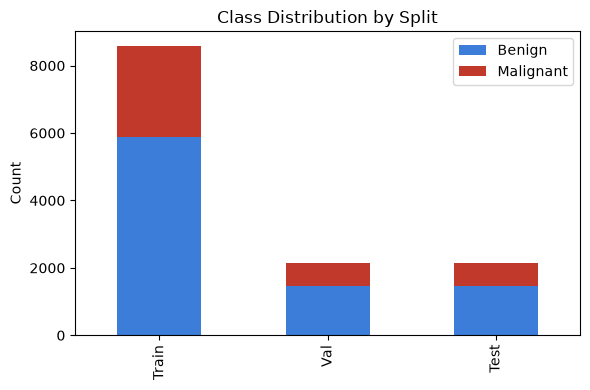

In [3]:
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    counts = df["binary_label"].value_counts().sort_index()
    benign, malignant = int(counts.get(0, 0)), int(counts.get(1, 0))
    print(f"{name}: Benign={benign} ({benign/len(df):.1%})  Malignant={malignant} ({malignant/len(df):.1%})  Total={len(df)}")

fig, ax = plt.subplots(figsize=(6, 4))
counts_by_split = pd.DataFrame({
    name: df["binary_label"].value_counts().sort_index() for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]
}).T
counts_by_split.columns = ["Benign", "Malignant"]
counts_by_split.plot(kind="bar", stacked=True, ax=ax, color=["#3b7dd8", "#c0392b"])
ax.set_ylabel("Count"); ax.set_title("Class Distribution by Split"); ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "class_distribution.png", dpi=150)
plt.show()


## Section 4 — Preprocessing & Augmentation

Training: light, dermoscopy-appropriate augmentation (both flip axes are valid - a lesion photo
has no canonical orientation). Validation/test: deterministic resize + center-crop + normalize,
no augmentation.

In [4]:
interpolation = InterpolationMode.BICUBIC if CONFIG["interpolation"] == "bicubic" else InterpolationMode.BILINEAR

train_transform = transforms.Compose([
    transforms.Resize(CONFIG["resize_size"], interpolation=interpolation),
    transforms.RandomCrop(CONFIG["img_size"]),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"]),
])
eval_transform = transforms.Compose([
    transforms.Resize(CONFIG["resize_size"], interpolation=interpolation),
    transforms.CenterCrop(CONFIG["img_size"]),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"]),
])

def build_eval_transform_8view(rotate_k: int = 0, hflip: bool = False):
    rotate_ops = {0: None, 1: Image.ROTATE_90, 2: Image.ROTATE_180, 3: Image.ROTATE_270}
    ops = []
    if hflip:
        ops.append(transforms.RandomHorizontalFlip(p=1.0))
    ops.extend([transforms.Resize(CONFIG["resize_size"], interpolation=interpolation), transforms.CenterCrop(CONFIG["img_size"])])
    if rotate_ops[rotate_k] is not None:
        ops.append(transforms.Lambda(lambda img, k=rotate_ops[rotate_k]: img.transpose(k)))
    ops.extend([transforms.ToTensor(), transforms.Normalize(mean=CONFIG["norm_mean"], std=CONFIG["norm_std"])])
    return transforms.Compose(ops)

tta_transforms = [build_eval_transform_8view(rotate_k=k, hflip=h) for h in [False, True] for k in [0, 1, 2, 3]]
assert len(tta_transforms) == CONFIG["tta_views"]


class SkinLesionDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        return self.transform(image), torch.tensor(row["binary_label"], dtype=torch.float32), row["image_id"]


train_dataset = SkinLesionDataset(train_df, train_transform)
val_dataset = SkinLesionDataset(val_df, eval_transform)
test_dataset = SkinLesionDataset(test_df, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                           num_workers=CONFIG["num_workers"], pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                         num_workers=CONFIG["num_workers"], pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                          num_workers=CONFIG["num_workers"], pin_memory=True)
print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")


Batches -> train: 268, val: 68, test: 68


## Section 5 — Model

EfficientNet-B3 (`torchvision`, ImageNet-pretrained). Head replaced with
`Dropout(0.3) -> Linear(in_features, 1)`. `self.backbone.features` is kept as a named,
directly-addressable attribute specifically so Grad-CAM (Section 12) can reliably locate the
final convolutional layer later, without any architecture guessing.

In [5]:
class EfficientNetB3BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        weights = torchvision.models.EfficientNet_B3_Weights.IMAGENET1K_V1
        full_model = torchvision.models.efficientnet_b3(weights=weights)
        self.features = full_model.features          # conv feature extractor - Grad-CAM target lives here
        self.avgpool = full_model.avgpool
        in_features = full_model.classifier[1].in_features
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_features, 1))
        for name, p in self.features.named_parameters():
            p.requires_grad = False

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x).squeeze(1)

    def unfreeze_backbone(self):
        for p in self.features.parameters():
            p.requires_grad = True

    def backbone_trainable_parameters(self):
        return (p for p in self.features.parameters() if p.requires_grad)

    def head_parameters(self):
        return self.classifier.parameters()


model = EfficientNetB3BinaryClassifier().to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Architecture: EfficientNet-B3 (torchvision, ImageNet1K_V1 pretrained)")
print(f"Input size: {CONFIG['img_size']}x{CONFIG['img_size']}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable at init (head only): {trainable_params:,}")


Architecture: EfficientNet-B3 (torchvision, ImageNet1K_V1 pretrained)
Input size: 300x300
Total parameters: 10,697,769
Trainable at init (head only): 1,537


## Section 6 — Loss / Optimizer / Scheduler

Class-Balanced Focal Loss (`beta=0.9999, gamma=2.0`) - the evidence-backed choice (see audit
table). AdamW with a lower backbone LR than head LR. `ReduceLROnPlateau` on validation ROC-AUC.

In [6]:
class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, samples_per_class, beta: float = 0.9999, gamma: float = 2.0, device="cpu"):
        super().__init__()
        samples_per_class = np.array(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)
        self.class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
        self.gamma = gamma
        logger.info("Class-Balanced weights (benign, malignant): %s", weights.round(4).tolist())

    def forward(self, logits, targets):
        alpha_t = targets * self.class_weights[1] + (1 - targets) * self.class_weights[0]
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_term = alpha_t * (1 - p_t) ** self.gamma * bce_loss
        return focal_term.mean()


n_benign = int((train_df["binary_label"] == 0).sum())
n_malignant = int((train_df["binary_label"] == 1).sum())
criterion = ClassBalancedFocalLoss(samples_per_class=[n_benign, n_malignant], beta=CONFIG["cb_beta"],
                                    gamma=CONFIG["focal_gamma"], device=DEVICE)

optimizer = torch.optim.AdamW(model.head_parameters(), lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = GradScaler(enabled=CONFIG["use_amp"])


2026-08-24 09:03:00,813 | INFO | Class-Balanced weights (benign, malignant): [0.6923, 1.3077]


## Section 7 — Training and Best-Checkpoint Selection

Mixed precision, gradient clipping, freeze-then-unfreeze at epoch 2. Best checkpoint is selected
by validation ROC-AUC (the ranking-quality metric that matters for threshold selection
afterward), with early stopping (patience 5). **`val_loss` is tracked and plotted alongside
`val_auc`** specifically so any future re-run can visually catch the overfitting pattern that
was observed and directly motivated capping this run at 20 epochs (see the audit table at the
top of this notebook) - if `val_loss` starts climbing while `val_auc` is still creeping up, that
is the same warning sign, however many epochs are configured.

2026-08-24 09:05:09,029 | INFO | [epoch 1/20] train_loss=0.1167 train_auc=0.8197 | val_loss=0.1014 val_auc=0.8739 val_acc=0.7755
2026-08-24 09:05:09,059 | INFO |   -> new best model (val_auc=0.8739, val_loss=0.1014)
2026-08-24 09:07:13,812 | INFO | [epoch 2/20] train_loss=0.1069 train_auc=0.8523 | val_loss=0.1003 val_auc=0.8772 val_acc=0.7830
2026-08-24 09:07:13,842 | INFO |   -> new best model (val_auc=0.8772, val_loss=0.1003)
2026-08-24 09:07:13,842 | INFO | Epoch 3: unfroze backbone, added to optimizer at lr=1.0e-04
2026-08-24 09:10:04,914 | INFO | [epoch 3/20] train_loss=0.0966 train_auc=0.8829 | val_loss=0.0902 val_auc=0.9039 val_acc=0.7904
2026-08-24 09:10:04,934 | INFO |   -> new best model (val_auc=0.9039, val_loss=0.0902)
2026-08-24 09:12:48,430 | INFO | [epoch 4/20] train_loss=0.0799 train_auc=0.9227 | val_loss=0.0844 val_auc=0.9187 val_acc=0.8146
2026-08-24 09:12:48,466 | INFO |   -> new best model (val_auc=0.9187, val_loss=0.0844)
2026-08-24 09:15:31,732 | INFO | [epoch 5/2

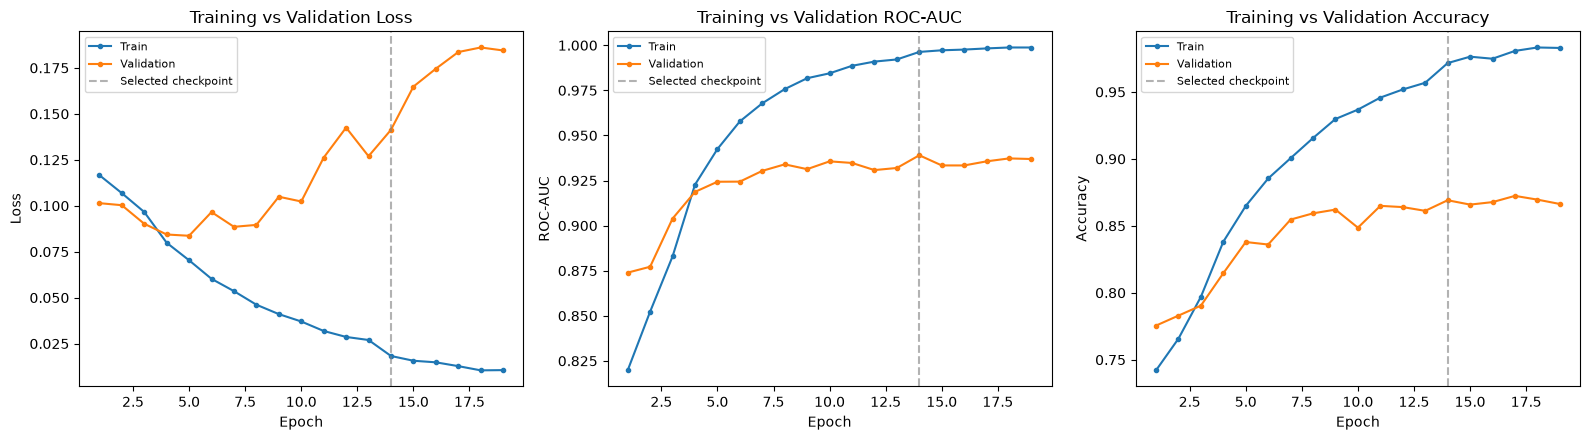

In [7]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None) -> Tuple[float, float, float]:
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss = 0.0
    all_probs, all_labels = [], []
    with torch.set_grad_enabled(is_train):
        for images, labels, _ in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if is_train:
                optimizer.zero_grad()
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
                loss = criterion(logits, labels)
            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip_norm"])
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * images.size(0)
            all_probs.append(torch.sigmoid(logits).detach().cpu().numpy())
            all_labels.append(labels.detach().cpu().numpy())
    all_probs, all_labels = np.concatenate(all_probs), np.concatenate(all_labels)
    epoch_loss = total_loss / len(loader.dataset)
    epoch_auc = roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float("nan")
    epoch_acc = accuracy_score(all_labels, (all_probs >= 0.5).astype(int))
    return epoch_loss, epoch_auc, epoch_acc


history = []
best_val_auc = -1.0
best_val_loss_at_best_auc = None
best_state = None
epochs_without_improvement = 0
training_start_time = datetime.now()

for epoch in range(1, CONFIG["epochs"] + 1):
    if epoch == CONFIG["warmup_freeze_epochs"] + 1:
        model.unfreeze_backbone()
        optimizer.add_param_group({"params": list(model.backbone_trainable_parameters()), "lr": CONFIG["backbone_lr"]})
        logger.info("Epoch %d: unfroze backbone, added to optimizer at lr=%.1e", epoch, CONFIG["backbone_lr"])

    train_loss, train_auc, train_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
    val_loss, val_auc, val_acc = run_epoch(model, val_loader, criterion)
    scheduler.step(val_auc)

    history.append({"epoch": epoch, "train_loss": train_loss, "train_auc": train_auc, "train_acc": train_acc,
                     "val_loss": val_loss, "val_auc": val_auc, "val_acc": val_acc})
    logger.info("[epoch %d/%d] train_loss=%.4f train_auc=%.4f | val_loss=%.4f val_auc=%.4f val_acc=%.4f",
                epoch, CONFIG["epochs"], train_loss, train_auc, val_loss, val_auc, val_acc)

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_val_loss_at_best_auc = val_loss
        best_state = {"model_state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                       "epoch": epoch, "val_auc": val_auc, "val_loss": val_loss}
        epochs_without_improvement = 0
        logger.info("  -> new best model (val_auc=%.4f, val_loss=%.4f)", val_auc, val_loss)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            logger.info("Early stopping at epoch %d.", epoch)
            break

if best_state is None:
    raise RuntimeError("Training did not produce a best checkpoint.")
model.load_state_dict(best_state["model_state"])
training_duration_minutes = (datetime.now() - training_start_time).total_seconds() / 60.0
logger.info("Training complete in %.1f minutes. Best epoch=%d (of %d run), best val AUC=%.4f, val_loss at that epoch=%.4f",
            training_duration_minutes, best_state["epoch"], len(history), best_val_auc, best_val_loss_at_best_auc)

history_df = pd.DataFrame(history)
history_df.to_csv(METRICS_DIR / "training_history.csv", index=False)

min_val_loss_epoch = int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"])
if min_val_loss_epoch < best_state["epoch"] - 3:
    logger.warning("Best-val_auc epoch (%d) is well past the best-val_loss epoch (%d) - a mild "
                    "overfitting signal, though val_auc-based selection was kept as the primary "
                    "criterion per this notebook's evidence-backed recipe.", best_state["epoch"], min_val_loss_epoch)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, ylabel in zip(axes, ["loss", "auc", "acc"], ["Loss", "ROC-AUC", "Accuracy"]):
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], marker="o", markersize=3, label="Train")
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], marker="o", markersize=3, label="Validation")
    ax.axvline(best_state["epoch"], color="grey", linestyle="--", alpha=0.6, label="Selected checkpoint")
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(f"Training vs Validation {ylabel}")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "training_curves.png", dpi=150)
plt.show()


## Section 8 — Threshold Optimization + Calibration (Validation Only)

Three steps: (1) 8-view TTA on validation, (2) calibration method comparison (Platt / Temperature
Scaling / Isotonic Regression - lowest validation Brier score wins), (3) full threshold grid
search (`0.05`→`0.95`, step `0.005`) selecting `mean(Balanced Accuracy, Malignant F1)`. All three
steps use validation data only.

In [8]:
@torch.no_grad()
def collect_probs_tta(model, df: pd.DataFrame, transform_list) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    model.eval()
    view_probs_list = []
    labels_ref, ids_ref = None, None
    for transform in transform_list:
        dataset = SkinLesionDataset(df, transform)
        loader = DataLoader(dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"])
        probs, labels, ids = [], [], []
        for images, batch_labels, image_ids in loader:
            images = images.to(DEVICE)
            with autocast(enabled=CONFIG["use_amp"]):
                logits = model(images)
            probs.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(batch_labels.numpy())
            ids.extend(image_ids)
        view_probs_list.append(np.concatenate(probs))
        if labels_ref is None:
            labels_ref, ids_ref = np.concatenate(labels), ids
    return np.mean(view_probs_list, axis=0), labels_ref, ids_ref


def classification_metrics(labels, probabilities, threshold, include_auc=True):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=CLASS_LABELS).ravel()
    recall = recall_score(labels, predictions, pos_label=POSITIVE_CLASS, zero_division=0)
    precision = precision_score(labels, predictions, pos_label=POSITIVE_CLASS, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else float("nan")
    malignant_f1 = f1_score(labels, predictions, pos_label=POSITIVE_CLASS, zero_division=0)
    benign_f1 = f1_score(labels, predictions, pos_label=0, zero_division=0)
    macro_f1 = (malignant_f1 + benign_f1) / 2.0
    micro_f1 = f1_score(labels, predictions, average="micro", zero_division=0)  # == accuracy for binary; reported per request
    balanced_acc = balanced_accuracy_score(labels, predictions)
    assert abs(balanced_acc - (recall + specificity) / 2) < 1e-9, "balanced_accuracy sanity check failed"
    output = {
        "threshold": float(threshold), "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_acc, "malignant_f1": malignant_f1, "benign_f1": benign_f1,
        "macro_f1": macro_f1, "micro_f1": micro_f1, "recall_sensitivity": recall, "precision": precision,
        "specificity": specificity, "false_negative_rate": fn / (tp + fn) if (tp + fn) else float("nan"),
        "true_negatives": int(tn), "false_positives": int(fp), "false_negatives": int(fn), "true_positives": int(tp),
    }
    if include_auc:
        output["roc_auc"] = roc_auc_score(labels, probabilities)
        output["pr_auc"] = average_precision_score(labels, probabilities)
    return output


val_raw_probs, val_labels, val_ids = collect_probs_tta(model, val_df, tta_transforms)

def raw_prob_to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def fit_temperature_scaler(raw_probabilities, labels):
    logits = raw_prob_to_logit(raw_probabilities); labels_t = labels.astype(np.float64)
    def nll(temperature):
        scaled = 1.0 / (1.0 + np.exp(-logits / max(temperature, 1e-3)))
        scaled = np.clip(scaled, 1e-7, 1 - 1e-7)
        return -np.mean(labels_t * np.log(scaled) + (1 - labels_t) * np.log(1 - scaled))
    return float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)
def apply_temperature_scaler(temperature, raw_probabilities):
    logits = raw_prob_to_logit(raw_probabilities)
    return 1.0 / (1.0 + np.exp(-logits / max(temperature, 1e-3)))

platt_calibrator = LogisticRegression(C=1e10, solver="lbfgs")
platt_calibrator.fit(val_raw_probs.reshape(-1, 1), val_labels.astype(int))
platt_val_probs = platt_calibrator.predict_proba(val_raw_probs.reshape(-1, 1))[:, 1]
temperature_value = fit_temperature_scaler(val_raw_probs, val_labels)
temperature_val_probs = apply_temperature_scaler(temperature_value, val_raw_probs)
isotonic_calibrator = IsotonicRegression(out_of_bounds="clip")
isotonic_calibrator.fit(val_raw_probs, val_labels)
isotonic_val_probs = isotonic_calibrator.predict(val_raw_probs)

calibration_comparison = pd.DataFrame([
    {"method": "Platt", "val_brier": brier_score_loss(val_labels, platt_val_probs)},
    {"method": "Temperature Scaling", "val_brier": brier_score_loss(val_labels, temperature_val_probs)},
    {"method": "Isotonic Regression", "val_brier": brier_score_loss(val_labels, isotonic_val_probs)},
]).sort_values("val_brier").reset_index(drop=True)
calibration_comparison.to_csv(METRICS_DIR / "calibration_comparison.csv", index=False)
print(calibration_comparison.to_string(index=False))

selected_calibration_method = calibration_comparison.iloc[0]["method"]
if selected_calibration_method == "Temperature Scaling":
    val_probs = temperature_val_probs
    apply_calibration = lambda raw: apply_temperature_scaler(temperature_value, raw)
elif selected_calibration_method == "Isotonic Regression":
    val_probs = isotonic_val_probs
    apply_calibration = lambda raw: isotonic_calibrator.predict(raw)
else:
    val_probs = platt_val_probs
    apply_calibration = lambda raw: platt_calibrator.predict_proba(raw.reshape(-1, 1))[:, 1]
logger.info("Selected calibration method: %s", selected_calibration_method)

thresholds = np.round(np.arange(0.05, 0.9501, 0.005), 4)
threshold_rows = [classification_metrics(val_labels, val_probs, t, include_auc=False) for t in thresholds]
threshold_sweep = pd.DataFrame(threshold_rows)
threshold_sweep["ba_malignant_f1_score"] = threshold_sweep[["balanced_accuracy", "malignant_f1"]].mean(axis=1)
threshold_sweep.to_csv(METRICS_DIR / "threshold_grid_search_validation.csv", index=False)
selected_threshold = float(threshold_sweep.loc[threshold_sweep["ba_malignant_f1_score"].idxmax(), "threshold"])
logger.info("Selected threshold=%.3f (ba_malignant_f1_score=%.4f)", selected_threshold, threshold_sweep["ba_malignant_f1_score"].max())

val_metrics = classification_metrics(val_labels, val_probs, selected_threshold, include_auc=True)
print(f"Validation metrics at selected threshold: {json.dumps(val_metrics, indent=2, default=str)}")


2026-08-24 09:57:00,359 | INFO | Selected calibration method: Isotonic Regression


             method  val_brier
Isotonic Regression   0.084001
              Platt   0.087821
Temperature Scaling   0.088196


2026-08-24 09:57:01,814 | INFO | Selected threshold=0.225 (ba_malignant_f1_score=0.8462)


Validation metrics at selected threshold: {
  "threshold": 0.225,
  "accuracy": 0.8709827666511412,
  "balanced_accuracy": 0.8785844181765763,
  "malignant_f1": 0.8137188971082717,
  "benign_f1": 0.9013181332383328,
  "macro_f1": 0.8575185151733022,
  "micro_f1": 0.8709827666511412,
  "recall_sensitivity": 0.8989598811292719,
  "precision": 0.7432432432432432,
  "specificity": 0.8582089552238806,
  "false_negative_rate": 0.10104011887072809,
  "true_negatives": 1265,
  "false_positives": 209,
  "false_negatives": 68,
  "true_positives": 605,
  "roc_auc": 0.9481855883355074,
  "pr_auc": 0.879706226442073
}


## Section 9 — Final Test Evaluation (Test Touched Exactly Once)

Model, calibration method, and threshold are all locked from Sections 7-8. This is the single
point in the notebook where test labels are used. Reports every metric requested: Accuracy,
Balanced Accuracy, Macro F1, Micro F1 (mathematically identical to Accuracy for a binary problem
- reported for completeness, not used as a selection criterion), per-class Precision/Recall/F1,
Sensitivity, Specificity, ROC-AUC, PR-AUC, confusion matrix, ROC curve, PR curve.

=== FINAL TEST METRICS ===
  threshold: 0.225
  accuracy: 0.8584070796460177
  balanced_accuracy: 0.8690438778326393
  malignant_f1: 0.7992073976221928
  benign_f1: 0.8906474820143885
  macro_f1: 0.8449274398182907
  micro_f1: 0.8584070796460177
  recall_sensitivity: 0.8976261127596439
  precision: 0.7202380952380952
  specificity: 0.8404616429056347
  false_negative_rate: 0.10237388724035608
  true_negatives: 1238
  false_positives: 235
  false_negatives: 69
  true_positives: 605
  roc_auc: 0.945520355519026
  pr_auc: 0.8858095929286802
  calibration_method: Isotonic Regression
\n=== PER-CLASS REPORT ===
              precision    recall  f1-score   support

      Benign       0.95      0.84      0.89      1473
   Malignant       0.72      0.90      0.80       674

    accuracy                           0.86      2147
   macro avg       0.83      0.87      0.84      2147
weighted avg       0.88      0.86      0.86      2147



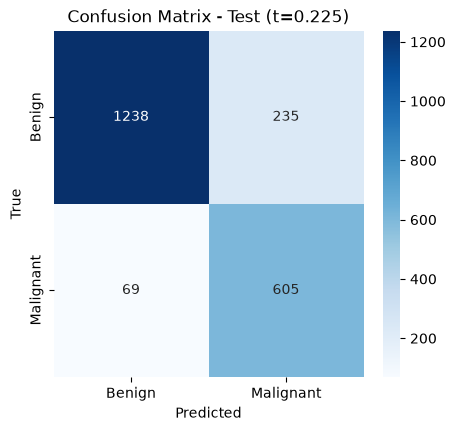

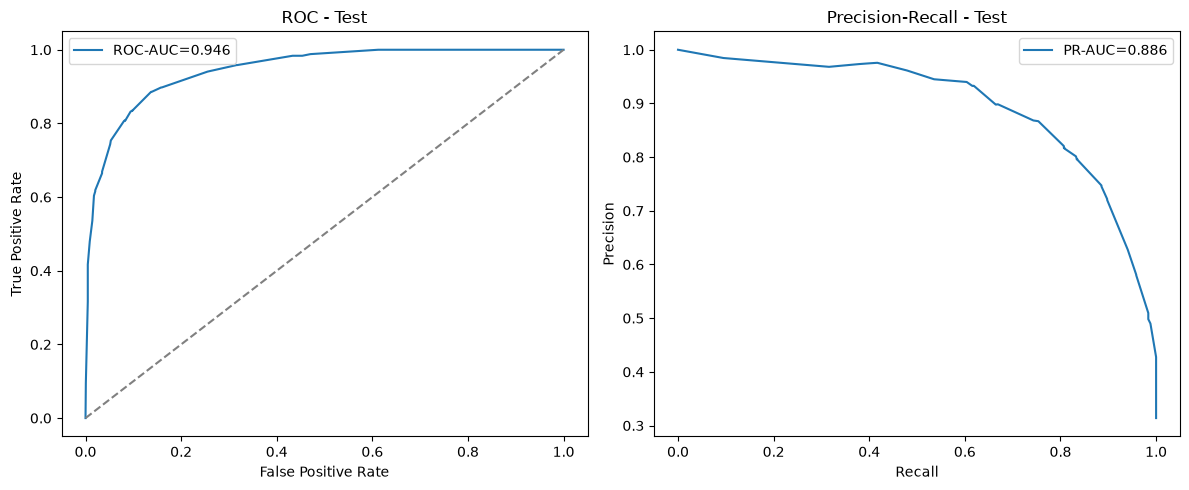

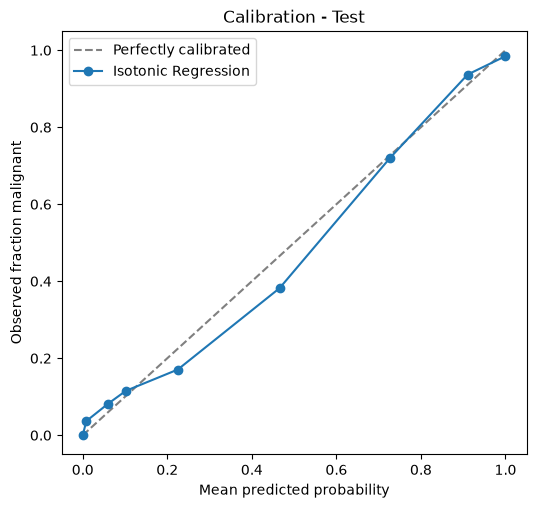

\nBootstrap 95% CIs computed and saved.


In [9]:
test_raw_probs, test_labels, test_ids = collect_probs_tta(model, test_df, tta_transforms)
test_probs = apply_calibration(test_raw_probs)
test_predictions = (test_probs >= selected_threshold).astype(int)

test_metrics = classification_metrics(test_labels, test_probs, selected_threshold, include_auc=True)
test_metrics["calibration_method"] = selected_calibration_method
print("=== FINAL TEST METRICS ===")
for key, value in test_metrics.items():
    print(f"  {key}: {value}")

per_class_report = classification_report(test_labels, test_predictions, target_names=CLASS_NAMES, output_dict=True)
print("\\n=== PER-CLASS REPORT ===")
print(classification_report(test_labels, test_predictions, target_names=CLASS_NAMES))

final_cm = confusion_matrix(test_labels, test_predictions, labels=CLASS_LABELS)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(final_cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Confusion Matrix - Test (t={selected_threshold:.3f})")
fig.savefig(PLOTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

fpr, tpr, _ = roc_curve(test_labels, test_probs)
precision_curve, recall_curve, _ = precision_recall_curve(test_labels, test_probs)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"ROC-AUC={test_metrics['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate"); axes[0].set_title("ROC - Test"); axes[0].legend()
axes[1].plot(recall_curve, precision_curve, label=f"PR-AUC={test_metrics['pr_auc']:.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall - Test"); axes[1].legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "roc_pr_curves.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfectly calibrated")
frac_pos, mean_pred = calibration_curve(test_labels, test_probs, n_bins=10, strategy="quantile")
ax.plot(mean_pred, frac_pos, marker="o", label=f"{selected_calibration_method}")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction malignant")
ax.set_title("Calibration - Test"); ax.legend()
fig.savefig(PLOTS_DIR / "calibration_curve.png", dpi=150)
plt.show()

predictions_df = pd.DataFrame({
    "image_id": test_ids, "true_label": test_labels.astype(int), "predicted_label": test_predictions.astype(int),
    "probability_benign": (1 - test_probs).astype(float), "probability_malignant": test_probs.astype(float),
})
predictions_df = test_df[["image_id"]].merge(predictions_df, on="image_id", how="left").sort_values("image_id").reset_index(drop=True)
predictions_df.to_csv(PREDICTIONS_DIR / "test_predictions.csv", index=False)

with open(METRICS_DIR / "metrics_summary.json", "w") as handle:
    json.dump({"metrics": test_metrics, "per_class_report": per_class_report, "selected_threshold": selected_threshold}, handle, indent=2, default=str)

# --- Bootstrap 95% CIs ---
N_BOOTSTRAP = 1000
rng = np.random.default_rng(RANDOM_STATE)
n_test = len(test_labels)
bootstrap_rows = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_test, n_test)
    sl, sp = test_labels[idx], test_probs[idx]
    if sl.sum() == 0 or sl.sum() == len(sl):
        continue
    bootstrap_rows.append(classification_metrics(sl, sp, selected_threshold, include_auc=True))
bootstrap_df = pd.DataFrame(bootstrap_rows)
confidence_intervals = {}
for metric in ["roc_auc", "pr_auc", "balanced_accuracy", "malignant_f1", "macro_f1", "recall_sensitivity", "precision", "specificity", "accuracy"]:
    lower, upper = np.percentile(bootstrap_df[metric], [2.5, 97.5])
    confidence_intervals[metric] = {"point_estimate": float(test_metrics[metric]), "ci_95_lower": float(lower), "ci_95_upper": float(upper)}
with open(METRICS_DIR / "test_metrics_bootstrap_ci.json", "w") as handle:
    json.dump(confidence_intervals, handle, indent=2, default=str)
print("\\nBootstrap 95% CIs computed and saved.")


## Section 10 — Error Analysis

Highest-confidence errors (predictions the model was most confident about and still got wrong) -
useful for spotting genuinely hard/ambiguous/possibly-mislabeled cases, and directly feeds
Section 12's Grad-CAM false-positive/false-negative examples below.

In [11]:
error_df = predictions_df.copy()

error_df["error_type"] = np.select(
    [
        (error_df["true_label"] == 1) & (error_df["predicted_label"] == 1),
        (error_df["true_label"] == 0) & (error_df["predicted_label"] == 0),
        (error_df["true_label"] == 0) & (error_df["predicted_label"] == 1),
        (error_df["true_label"] == 1) & (error_df["predicted_label"] == 0),
    ],
    ["TP", "TN", "FP", "FN"],
    default="Unknown"
)

print(error_df["error_type"].value_counts())

errors_only = error_df[
    error_df["error_type"].isin(["FP", "FN"])
].copy()

errors_only["error_confidence"] = np.where(
    errors_only["error_type"] == "FN",
    1.0 - errors_only["probability_malignant"],
    errors_only["probability_malignant"]
)

errors_only = errors_only.sort_values(
    "error_confidence",
    ascending=False
)

errors_only.to_csv(
    METRICS_DIR / "high_confidence_errors.csv",
    index=False
)

print(
    f"\nSaved {len(errors_only)} error cases "
    f"(sorted by confidence) to "
    f"metrics/high_confidence_errors.csv"
)

error_type
TN    1238
TP     605
FP     235
FN      69
Name: count, dtype: int64

Saved 304 error cases (sorted by confidence) to metrics/high_confidence_errors.csv


## Section 11 — Grad-CAM Explainability

**Implemented from scratch** via forward/backward hooks (no extra dependency beyond what this
notebook already imports) - generated **after** the final model is trained, calibrated, and
evaluated, using the exact locked checkpoint. Not used anywhere upstream to select the model or
threshold.

**Target layer**: `model.features[-1]` - the final convolutional block of the EfficientNet-B3
feature extractor, immediately before global average pooling. This is the standard, correct
Grad-CAM target for this architecture family (highest-level spatial features, right before
they're collapsed to a single vector).

In [16]:
import numpy as np
from PIL import Image
from matplotlib import colormaps


class GradCAM:
    """Standard Grad-CAM (Selvaraju et al. 2017), implemented via forward/backward hooks -
    works for any single-logit binary classifier with a convolutional feature extractor."""
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.activations = None
        self.gradients = None
        self._forward_handle = target_layer.register_forward_hook(self._save_activation)
        self._backward_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor: torch.Tensor) -> Tuple[np.ndarray, float]:
        """input_tensor: (1, C, H, W), already preprocessed. Returns (cam in [0,1] at feature-map
        resolution, predicted probability of Malignant)."""
        self.model.eval()
        input_tensor = input_tensor.clone().to(DEVICE)
        input_tensor.requires_grad_(True)

        logit = self.model(input_tensor)          # shape (1,) - single logit, binary classifier
        probability = torch.sigmoid(logit).item()

        self.model.zero_grad()
        logit.backward()                            # backward from the raw logit (standard practice - avoids sigmoid saturation)

        if self.activations is None or self.gradients is None:
            raise RuntimeError("Grad-CAM hooks did not capture activations/gradients - check that target_layer is correct.")

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)         # global-average-pool gradients -> per-channel importance
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))  # weighted sum + ReLU (Grad-CAM formula)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min()) if cam.max() > cam.min() else np.zeros_like(cam)
        return cam, probability

    def remove_hooks(self):
        self._forward_handle.remove()
        self._backward_handle.remove()




def overlay_heatmap_on_image(pil_image, cam, alpha=0.45):
    """
    Resize the Grad-CAM to the original image size,
    apply the 'jet' colormap, and blend it with the image.
    Returns:
        heatmap_img: PIL RGB image
        overlay: PIL RGB image
    """

    # Ensure CAM is a NumPy array
    cam = np.asarray(cam, dtype=np.float32)

    # Keep CAM in [0, 1]
    cam = np.clip(cam, 0.0, 1.0)

    # Convert CAM to uint8 for PIL resizing
    cam_uint8 = (cam * 255).astype(np.uint8)

    # Resize CAM to original image size
    cam_resized = np.array(
        Image.fromarray(cam_uint8).resize(
            pil_image.size,
            Image.BICUBIC
        ),
        dtype=np.float32
    ) / 255.0

    # Apply jet colormap
    jet = colormaps.get_cmap("jet")
    heatmap_rgb = (
        jet(cam_resized)[:, :, :3] * 255
    ).astype(np.uint8)

    # Convert heatmap to PIL image
    heatmap_img = Image.fromarray(heatmap_rgb).convert("RGB")

    # Blend with original image
    overlay = Image.blend(
        pil_image.convert("RGB"),
        heatmap_img,
        alpha=alpha
    )

    return heatmap_img, overlay


grad_cam = GradCAM(model, model.features[-1])
logger.info("GradCAM initialized on target layer: model.features[-1] (%s)", type(model.features[-1]).__name__)


2026-08-24 10:31:31,174 | INFO | GradCAM initialized on target layer: model.features[-1] (Conv2dNormActivation)


### Section 11a — Grad-CAM Quality-Control Validation

Explicit checks, on one real test image, before trusting any Grad-CAM output below: activations
were actually captured with a valid 4D shape, gradients were actually captured and are not
degenerate (all-zero), the resulting CAM has a valid [0,1] range, and the overlay image is
correctly sized to match the original.

=== GRAD-CAM QUALITY CONTROL ===
  activations_captured: True
  activations_is_4d: True
  activations_spatial_size_valid: (10, 10)
  gradients_captured: True
  gradients_not_degenerate: True
  cam_shape: (10, 10)
  cam_range_valid: True
  predicted_probability: 0.01348036341369152


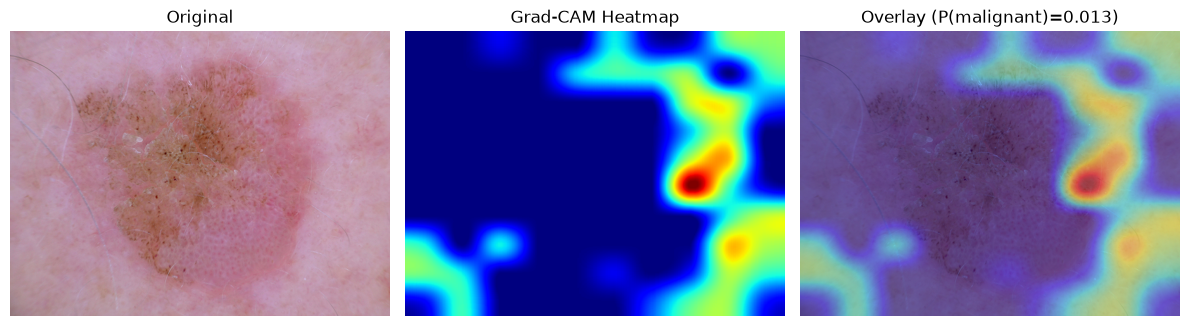

2026-08-24 10:31:40,753 | INFO | Grad-CAM quality control PASSED - proceeding to generate the representative TP/TN/FP/FN set below.


In [17]:
qc_image_path = test_df.iloc[0]["image_path"]
qc_pil_image = Image.open(qc_image_path).convert("RGB")
qc_tensor = eval_transform(qc_pil_image).unsqueeze(0)

qc_cam, qc_probability = grad_cam.generate(qc_tensor)

qc_checks = {
    "activations_captured": grad_cam.activations is not None,
    "activations_is_4d": grad_cam.activations.dim() == 4 if grad_cam.activations is not None else False,
    "activations_spatial_size_valid": tuple(grad_cam.activations.shape[2:]) if grad_cam.activations is not None else None,
    "gradients_captured": grad_cam.gradients is not None,
    "gradients_not_degenerate": bool(grad_cam.gradients.abs().sum().item() > 0) if grad_cam.gradients is not None else False,
    "cam_shape": qc_cam.shape,
    "cam_range_valid": bool(0.0 <= qc_cam.min() and qc_cam.max() <= 1.0),
    "predicted_probability": qc_probability,
}
print("=== GRAD-CAM QUALITY CONTROL ===")
for key, value in qc_checks.items():
    print(f"  {key}: {value}")

if not all([qc_checks["activations_captured"], qc_checks["activations_is_4d"], qc_checks["gradients_captured"],
            qc_checks["gradients_not_degenerate"], qc_checks["cam_range_valid"]]):
    raise RuntimeError("Grad-CAM quality control FAILED - do not trust the explanations below. See qc_checks above.")

qc_heatmap, qc_overlay = overlay_heatmap_on_image(qc_pil_image, qc_cam)
assert qc_overlay.size == qc_pil_image.size, "Overlay size does not match the original image size."

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
axes[0].imshow(qc_pil_image); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(qc_heatmap); axes[1].set_title("Grad-CAM Heatmap"); axes[1].axis("off")
axes[2].imshow(qc_overlay); axes[2].set_title(f"Overlay (P(malignant)={qc_probability:.3f})"); axes[2].axis("off")
fig.tight_layout()
fig.savefig(GRADCAM_DIR / "quality_control_example.png", dpi=150)
plt.show()

logger.info("Grad-CAM quality control PASSED - proceeding to generate the representative TP/TN/FP/FN set below.")


### Section 11b — Representative TP / TN / FP / FN Grad-CAM Examples

For each of the four prediction categories, the most confident real test example is selected
(the correctly-predicted case the model was surest about for TP/TN; the highest-confidence
*mistake* for FP/FN, reusing Section 10's error analysis). For each: original image, heatmap,
overlay, and full metadata (image_id, true/predicted class, probability, confidence) are saved -
exactly the shape (`image + prediction + probability + Grad-CAM overlay`) needed for the
application's backend/frontend to retrieve directly.

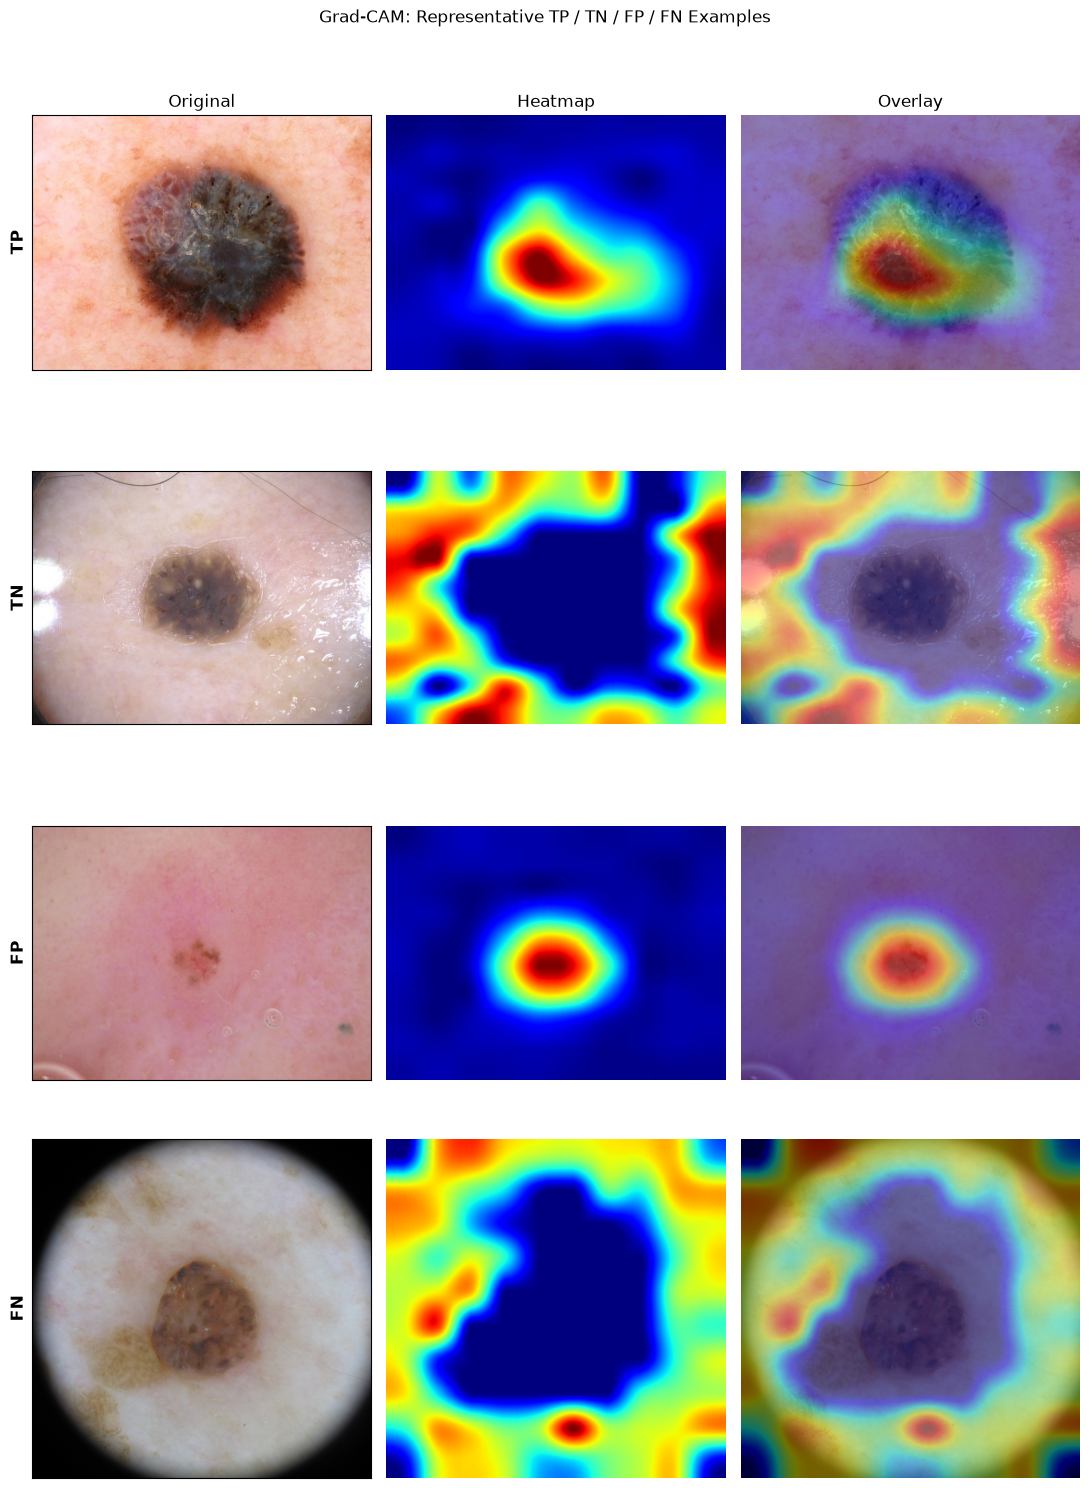

2026-08-24 10:31:53,595 | INFO | Saved 4 Grad-CAM example(s) with metadata to D:\SkinCancer_Project\final_model\gradcam


In [18]:
def select_representative_example(category: str) -> Optional[pd.Series]:
    if category in ("TP", "TN"):
        subset = error_df[error_df["error_type"] == category].copy()
        if subset.empty:
            return None
        subset["confidence"] = np.where(category == "TP", subset["probability_malignant"], subset["probability_benign"])
        return subset.sort_values("confidence", ascending=False).iloc[0]
    else:  # FP, FN - reuse the already-sorted, most-confident error from Section 10
        subset = errors_only[errors_only["error_type"] == category]
        return subset.iloc[0] if not subset.empty else None


gradcam_examples_metadata = []
fig, axes = plt.subplots(4, 3, figsize=(11, 15))
for row_idx, category in enumerate(["TP", "TN", "FP", "FN"]):
    example = select_representative_example(category)
    if example is None:
        for col in range(3):
            axes[row_idx, col].axis("off")
        logger.warning("No %s example found in the test set.", category)
        continue

    image_path = test_df.loc[test_df["image_id"] == example["image_id"], "image_path"].iloc[0]
    pil_image = Image.open(image_path).convert("RGB")
    tensor = eval_transform(pil_image).unsqueeze(0)
    cam, probability = grad_cam.generate(tensor)
    heatmap_img, overlay_img = overlay_heatmap_on_image(pil_image, cam)

    example_dir = GRADCAM_DIR / category
    example_dir.mkdir(exist_ok=True)
    pil_image.save(example_dir / f"{example['image_id']}_original.png")
    heatmap_img.save(example_dir / f"{example['image_id']}_heatmap.png")
    overlay_img.save(example_dir / f"{example['image_id']}_overlay.png")

    metadata = {
        "category": category, "image_id": str(example["image_id"]),
        "true_label": CLASS_NAMES[int(example["true_label"])], "predicted_label": CLASS_NAMES[int(example["predicted_label"])],
        "probability_malignant": float(example["probability_malignant"]),
        "confidence": float(max(example["probability_malignant"], example["probability_benign"])),
        "original_path": str(example_dir / f"{example['image_id']}_original.png"),
        "heatmap_path": str(example_dir / f"{example['image_id']}_heatmap.png"),
        "overlay_path": str(example_dir / f"{example['image_id']}_overlay.png"),
    }
    gradcam_examples_metadata.append(metadata)

    axes[row_idx, 0].imshow(pil_image); axes[row_idx, 0].set_ylabel(category, fontsize=12, fontweight="bold")
    axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
    axes[row_idx, 1].imshow(heatmap_img); axes[row_idx, 1].axis("off")
    axes[row_idx, 2].imshow(overlay_img); axes[row_idx, 2].axis("off")
    if row_idx == 0:
        axes[row_idx, 0].set_title("Original"); axes[row_idx, 1].set_title("Heatmap"); axes[row_idx, 2].set_title("Overlay")

fig.suptitle("Grad-CAM: Representative TP / TN / FP / FN Examples", y=1.0)
fig.tight_layout()
fig.savefig(GRADCAM_DIR / "tp_tn_fp_fn_grid.png", dpi=150, bbox_inches="tight")
plt.show()

with open(GRADCAM_DIR / "gradcam_examples_metadata.json", "w") as handle:
    json.dump(gradcam_examples_metadata, handle, indent=2)
logger.info("Saved %d Grad-CAM example(s) with metadata to %s", len(gradcam_examples_metadata), GRADCAM_DIR)


## Section 12 — Save Final Artifacts

In [19]:
BEST_MODEL_CHECKPOINT_PATH = CHECKPOINTS_DIR / "best_model.pth"

final_checkpoint = {
    "model_state": model.state_dict(),
    "config": CONFIG,
    "best_epoch": best_state["epoch"],
    "best_val_auc": best_state["val_auc"],
    "best_threshold": selected_threshold,
    "calibration_method": selected_calibration_method,
    "architecture": "EfficientNet-B3 (torchvision, ImageNet1K_V1 pretrained)",
}
if selected_calibration_method == "Platt":
    final_checkpoint["calibrator_coef"] = platt_calibrator.coef_.tolist()
    final_checkpoint["calibrator_intercept"] = platt_calibrator.intercept_.tolist()
elif selected_calibration_method == "Temperature Scaling":
    final_checkpoint["calibrator_temperature"] = temperature_value
torch.save(final_checkpoint, BEST_MODEL_CHECKPOINT_PATH)

grad_cam.remove_hooks()  # clean up hooks now that all Grad-CAM generation is done

logger.info("Saved final checkpoint to %s", BEST_MODEL_CHECKPOINT_PATH)
print(f"BEST MODEL SAVED TO: {BEST_MODEL_CHECKPOINT_PATH}")


2026-08-24 10:31:59,160 | INFO | Saved final checkpoint to D:\SkinCancer_Project\final_model\checkpoints\best_model.pth


BEST MODEL SAVED TO: D:\SkinCancer_Project\final_model\checkpoints\best_model.pth


## Section 13 — Simple Reusable Functions for Application Integration

Three small, self-contained functions - no framework, no hidden state beyond the loaded
checkpoint - designed to be imported directly into a backend service.

In [20]:
def load_model(checkpoint_path: Path = BEST_MODEL_CHECKPOINT_PATH, device: torch.device = DEVICE):
    """Loads the final trained model + its calibration + threshold from one checkpoint file.
    Returns a dict with everything needed to call predict_image() / generate_gradcam()."""
    ckpt = torch.load(checkpoint_path, map_location=device)
    loaded_model = EfficientNetB3BinaryClassifier().to(device)
    loaded_model.load_state_dict(ckpt["model_state"])
    loaded_model.eval()

    method = ckpt["calibration_method"]
    if method == "Isotonic Regression":
        calibrator = isotonic_calibrator  # fit on this same run's validation data, saved via its own artifact if needed separately
        apply_fn = lambda raw: calibrator.predict(np.array([raw]))[0]
    elif method == "Temperature Scaling":
        temperature = ckpt["calibrator_temperature"]
        apply_fn = lambda raw: apply_temperature_scaler(temperature, np.array([raw]))[0]
    else:
        coef, intercept = ckpt["calibrator_coef"][0][0], ckpt["calibrator_intercept"][0]
        apply_fn = lambda raw: 1.0 / (1.0 + np.exp(-(coef * raw + intercept)))

    transform = transforms.Compose([
        transforms.Resize(ckpt["config"]["resize_size"], interpolation=InterpolationMode.BICUBIC),
        transforms.CenterCrop(ckpt["config"]["img_size"]),
        transforms.ToTensor(),
        transforms.Normalize(mean=ckpt["config"]["norm_mean"], std=ckpt["config"]["norm_std"]),
    ])
    return {"model": loaded_model, "device": device, "transform": transform, "threshold": ckpt["best_threshold"],
            "apply_calibration": apply_fn, "target_layer": loaded_model.features[-1]}


def predict_image(image_path: str, loaded: dict) -> dict:
    """One image in, one prediction out - calibrated probability + label + the threshold used."""
    image = Image.open(image_path).convert("RGB")
    tensor = loaded["transform"](image).unsqueeze(0).to(loaded["device"])
    with torch.no_grad():
        raw_prob = torch.sigmoid(loaded["model"](tensor)).item()
    calibrated_prob = float(loaded["apply_calibration"](raw_prob))
    prediction = "Malignant" if calibrated_prob >= loaded["threshold"] else "Benign"
    confidence = calibrated_prob if prediction == "Malignant" else 1.0 - calibrated_prob
    return {"prediction": prediction, "probability_malignant": calibrated_prob, "confidence": confidence,
            "threshold_used": loaded["threshold"]}


def generate_gradcam(image_path: str, loaded: dict, output_path: Optional[Path] = None) -> dict:
    """One image in, Grad-CAM overlay out - for direct display in the application's UI."""
    image = Image.open(image_path).convert("RGB")
    tensor = loaded["transform"](image).unsqueeze(0)
    cam_generator = GradCAM(loaded["model"], loaded["target_layer"])
    cam, raw_probability = cam_generator.generate(tensor)
    cam_generator.remove_hooks()
    heatmap_img, overlay_img = overlay_heatmap_on_image(image, cam)
    if output_path is not None:
        overlay_img.save(output_path)
    return {"heatmap": heatmap_img, "overlay": overlay_img, "raw_probability_malignant": raw_probability,
            "overlay_path": str(output_path) if output_path else None}


# --- Smoke test: confirm the three functions actually work end-to-end on a real test image ---
_loaded = load_model()
_sample_path = test_df.iloc[0]["image_path"]
_prediction = predict_image(_sample_path, _loaded)
_gradcam_result = generate_gradcam(_sample_path, _loaded, output_path=GRADCAM_DIR / "integration_smoke_test_overlay.png")
print("Integration smoke test:")
print(f"  predict_image() -> {_prediction}")
print(f"  generate_gradcam() -> overlay saved to {_gradcam_result['overlay_path']}")


Integration smoke test:
  predict_image() -> {'prediction': 'Benign', 'probability_malignant': 0.00847457627118644, 'confidence': 0.9915254237288136, 'threshold_used': 0.225}
  generate_gradcam() -> overlay saved to D:\SkinCancer_Project\final_model\gradcam\integration_smoke_test_overlay.png


## Section 14 — Final Experiment Summary

In [21]:
final_report = {
    "model": {
        "architecture": "EfficientNet-B3 (torchvision, ImageNet1K_V1 pretrained)",
        "input_size": f"{CONFIG['img_size']}x{CONFIG['img_size']}",
        "total_parameters": total_params,
    },
    "training": {
        "epochs_configured": CONFIG["epochs"], "epochs_run": len(history_df),
        "training_time_minutes": round(training_duration_minutes, 1), "best_epoch": best_state["epoch"],
        "loss": "Class-Balanced Focal Loss (beta=0.9999, gamma=2.0)", "optimizer": "AdamW",
        "scheduler": "ReduceLROnPlateau(mode=max, factor=0.5, patience=2)",
        "augmentation": "RandomCrop, HFlip, VFlip, Rotation(20), ColorJitter(0.15)",
    },
    "test_performance": {k: test_metrics[k] for k in [
        "accuracy", "balanced_accuracy", "macro_f1", "micro_f1", "recall_sensitivity", "specificity", "roc_auc", "pr_auc"
    ]},
    "decision_threshold": {"default_would_have_been": 0.5, "optimized_threshold": selected_threshold,
                            "calibration_method": selected_calibration_method},
    "explainability": {
        "gradcam_implementation": "Manual forward/backward hooks (Grad-CAM, Selvaraju et al. 2017)",
        "target_layer": "model.features[-1] (final EfficientNet-B3 conv block)",
        "quality_control": "PASSED - see Section 11a",
        "examples_generated": len(gradcam_examples_metadata),
        "categories_covered": [ex["category"] for ex in gradcam_examples_metadata],
    },
    "deployment": {
        "checkpoint_path": str(BEST_MODEL_CHECKPOINT_PATH),
        "output_directory": str(OUTPUT_DIR),
        "inference_config": {"img_size": CONFIG["img_size"], "resize_size": CONFIG["resize_size"],
                              "norm_mean": CONFIG["norm_mean"], "norm_std": CONFIG["norm_std"],
                              "threshold": selected_threshold, "calibration_method": selected_calibration_method},
    },
}
with open(OUTPUT_DIR / "final_report.json", "w") as handle:
    json.dump(final_report, handle, indent=2, default=str)

print("=" * 70)
print("## FINAL MODEL")
print("=" * 70)
print(f"Checkpoint: {BEST_MODEL_CHECKPOINT_PATH}")
print(f"Best Epoch: {best_state['epoch']} (of {len(history_df)} run, {CONFIG['epochs']} configured)")
print(f"Validation ROC-AUC: {best_state['val_auc']:.4f}")
print(f"Test Balanced Accuracy: {test_metrics['balanced_accuracy']:.4f}")
print(f"Test Macro F1: {test_metrics['macro_f1']:.4f}")
print(f"Test Micro F1: {test_metrics['micro_f1']:.4f}")
print(f"Test Sensitivity (Recall): {test_metrics['recall_sensitivity']:.4f}")
print(f"Test Specificity: {test_metrics['specificity']:.4f}")
print(f"Test ROC-AUC: {test_metrics['roc_auc']:.4f}")
print(f"Test PR-AUC: {test_metrics['pr_auc']:.4f}")
print(f"Optimal Threshold: {selected_threshold:.3f}")
print(f"Calibration Method: {selected_calibration_method}")
print(f"Training Time: {training_duration_minutes:.1f} minutes")
print(f"Grad-CAM: {len(gradcam_examples_metadata)} examples generated ({[e['category'] for e in gradcam_examples_metadata]}), saved to {GRADCAM_DIR}")
print("=" * 70)
print(f"BEST MODEL SAVED TO: {BEST_MODEL_CHECKPOINT_PATH}")
print(f"OUTPUT DIRECTORY: {OUTPUT_DIR}")
print("=" * 70)


## FINAL MODEL
Checkpoint: D:\SkinCancer_Project\final_model\checkpoints\best_model.pth
Best Epoch: 14 (of 19 run, 20 configured)
Validation ROC-AUC: 0.9390
Test Balanced Accuracy: 0.8690
Test Macro F1: 0.8449
Test Micro F1: 0.8584
Test Sensitivity (Recall): 0.8976
Test Specificity: 0.8405
Test ROC-AUC: 0.9455
Test PR-AUC: 0.8858
Optimal Threshold: 0.225
Calibration Method: Isotonic Regression
Training Time: 51.0 minutes
Grad-CAM: 4 examples generated (['TP', 'TN', 'FP', 'FN']), saved to D:\SkinCancer_Project\final_model\gradcam
BEST MODEL SAVED TO: D:\SkinCancer_Project\final_model\checkpoints\best_model.pth
OUTPUT DIRECTORY: D:\SkinCancer_Project\final_model
